**CLAP-general variant (phase4d_coherence_artist_folds_cg).** Copy of `phase4d_coherence_artist_folds.ipynb` with the CLAP audio representation replaced by `laion/larger_clap_general` (`audio_features_clap_general.parquet`; the HF `larger_clap_music` conversion is defective, see Phase 2d and 5p). Only the CLAP audio probe changes; the MuQ coherence outputs must equal the originals. Every output carries a `_cg` suffix; the original outputs are untouched.

# Phase 4d: Cross-modal coherence with artist-grouped cross-fitting

Review comment: the coherence probes of Phase 4c were cross-fitted with folds stratified by quadrant only. Because
MERGE repeats artists (1,086 artists for 2,075 tracks), a track's probe could be trained on other tracks by the same
artist and use artist identity. This notebook repeats the Phase 4c protocol with **folds grouped by artist**
(`StratifiedGroupKFold`, 5 folds, stratified by quadrant within that constraint): no track is scored by a probe that saw
any track by its artist.

Everything else is identical to 4c: ridge grid, 200 bootstrap probes per fold, cosine and Euclidean coherence, the
(0.5, 0.5) center, status rules. All probe variants are fitted in one loop with shared bootstrap draws:
* MuQ L7 (audio) + SBERT (lyrics): the main score (replaces `coherence_muq.parquet`);
* CLAP (audio, random crop, as in 4b) + SBERT: replaces `coherence_v2.parquet` for the encoder comparison;
* MuQ + emotion DistilRoBERTa (lyrics): replaces `coherence_muq_emoroberta.parquet`;
* MuQ + chunked SBERT (lyrics): replaces `coherence_muq_sbert_chunk.parquet`.

It also re-checks the probe accuracy on the 70/15/15 test split with training restricted to artists that do not
appear in the test split, and repeats the 4c summaries (quadrants, genres), Figure 7 and the 6b boundary analysis.

All outputs carry an `_af` (artist folds) suffix; 4b, 4c, 5g and 6b outputs are not modified. `genres` is read only in
the genre section (evaluation metadata).

In [1]:
import os, re, unicodedata, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, kruskal, mannwhitneyu
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.metrics import r2_score, mean_absolute_error, pairwise_distances, silhouette_samples
warnings.filterwarnings('ignore')

ROOT = os.environ.get('MUSIC_RESEARCH_ROOT', os.path.abspath('.'))
OUT_DIR = os.path.join(ROOT, 'outputs')
ENC_DIR = os.path.join(OUT_DIR, 'encoders')
SEED, N_BOOT, N_FOLDS = 42, 200, 5
RIDGE_ALPHAS = np.logspace(-2, 5, 15)
CENTER = np.array([0.5, 0.5])
QUADS  = ['Q1', 'Q2', 'Q3', 'Q4']
QLAB   = {'Q1': 'Happy', 'Q2': 'Angry', 'Q3': 'Sad', 'Q4': 'Calm'}
QCOL   = {'Q1': '#f4a261', 'Q2': '#e63946', 'Q3': '#457b9d', 'Q4': '#2a9d8f'}

lyrics_df = pd.read_parquet(os.path.join(OUT_DIR, 'lyrics_features.parquet'))
merged    = pd.read_parquet(os.path.join(OUT_DIR, 'merged_dataset.parquet'))
audio_df  = pd.read_parquet(os.path.join(OUT_DIR, 'audio_features.parquet')).set_index('song_id')
sids = lyrics_df['song_id'].tolist(); n = len(sids)
assert pd.read_csv(os.path.join(ENC_DIR, 'text_song_ids.csv'))['song_id'].tolist() == sids
a_ids = pd.read_csv(os.path.join(ENC_DIR, 'audio_song_ids.csv'))['song_id'].tolist()
arow  = {s: i for i, s in enumerate(a_ids)}
muq   = np.load(os.path.join(ENC_DIR, 'audio_muq.npy'), mmap_mode='r')[[arow[s] for s in sids]]
X = {'muq':   muq[:, 7].astype(np.float64),                                   # 4c audio probe (layer 7)
     'clap':  np.vstack(pd.read_parquet(os.path.join(OUT_DIR, 'audio_features_clap_general.parquet')).set_index('song_id').loc[sids, 'audio_clap_gen'].values).astype(np.float64),   # 4b audio probe
     'sbert': np.vstack(lyrics_df['lyrics_sbert'].values).astype(np.float64),   # 4c lyric probe
     'emo':   np.load(os.path.join(ENC_DIR, 'text_emoroberta_emb.npy')).astype(np.float64),
     'chunk': np.load(os.path.join(ENC_DIR, 'text_sbert_mpnet_chunk.npy')).astype(np.float64)}
lab  = merged.set_index('song_id').loc[sids]
Y    = lab[['arousal', 'valence']].values.astype(np.float64)
quad = lab['quadrant'].values

def norm_artist(s):
    s = unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode().lower().strip()
    return re.sub(r'[^a-z0-9]+', ' ', re.sub(r'^the\s+', '', s)).strip()
ART_ID = np.array([norm_artist(a) for a in lab['artist'].values])

def make_probe(alpha=None):
    return make_pipeline(StandardScaler(), RidgeCV(alphas=RIDGE_ALPHAS) if alpha is None else Ridge(alpha=alpha))
def cos_coh(A, L):
    A, L = A - CENTER, L - CENTER
    return (A * L).sum(-1) / (np.linalg.norm(A, axis=-1) * np.linalg.norm(L, axis=-1) + 1e-12)
def euc_coh(A, L):
    return -np.linalg.norm(A - L, axis=-1)
def to_quad(av):
    return np.where(av[:, 0] >= .5, np.where(av[:, 1] >= .5, 'Q1', 'Q2'), np.where(av[:, 1] >= .5, 'Q4', 'Q3'))

FOLDS_STRAT = list(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(X['muq'], quad))
FOLDS_ART   = list(StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=SEED).split(X['muq'], quad, ART_ID))
for k, (itr, ite) in enumerate(FOLDS_ART):
    assert not set(ART_ID[itr]) & set(ART_ID[ite])
print('artist-grouped folds: sizes', [len(ite) for _, ite in FOLDS_ART], '; no artist in both parts of any fold')

artist-grouped folds: sizes [415, 415, 416, 415, 414] ; no artist in both parts of any fold


## 0. Check: the fold machinery reproduces Phase 4c with its original stratified folds (point predictions)

In [2]:
ref = pd.read_parquet(os.path.join(OUT_DIR, 'coherence_muq.parquet')).set_index('song_id').loc[sids]
P = {k: np.zeros((n, 2)) for k in ['muq', 'sbert']}
for itr, ite in FOLDS_STRAT:
    for k in P:
        P[k][ite] = make_probe().fit(X[k][itr], Y[itr]).predict(X[k][ite])
assert np.allclose(P['muq'], ref[['pred_audio_arousal', 'pred_audio_valence']].values)
assert np.allclose(P['sbert'], ref[['pred_lyrics_arousal', 'pred_lyrics_valence']].values)
print('Stratified folds reproduce Phase 4c point predictions exactly.')

Stratified folds reproduce Phase 4c point predictions exactly.


## 1. Cross-fitted predictions with artist-grouped folds, 200 bootstrap probes per fold

In [3]:
rng = np.random.default_rng(SEED)
KEYS = list(X)
pred = {k: np.zeros((n, 2)) for k in KEYS}
boot = {k: np.zeros((N_BOOT, n, 2), dtype=np.float32) for k in KEYS}
for f, (itr, ite) in enumerate(FOLDS_ART):
    probes = {k: make_probe().fit(X[k][itr], Y[itr]) for k in KEYS}
    for k, p in probes.items():
        pred[k][ite] = p.predict(X[k][ite])
    for b in range(N_BOOT):
        ib = rng.choice(itr, size=len(itr), replace=True)
        for k, p in probes.items():
            boot[k][b, ite] = make_probe(p[-1].alpha_).fit(X[k][ib], Y[ib]).predict(X[k][ite])
    print(f'fold {f}: ridge α ' + ', '.join(f'{k}={p[-1].alpha_:.0f}' for k, p in probes.items()), flush=True)

oof = []
for k in KEYS:
    for folds, nm in [(FOLDS_STRAT, 'stratified (4c)'), (FOLDS_ART, 'artist-grouped')]:
        if nm == 'stratified (4c)':
            Pk = np.zeros((n, 2))
            for itr, ite in folds:
                Pk[ite] = make_probe().fit(X[k][itr], Y[itr]).predict(X[k][ite])
        else:
            Pk = pred[k]
        oof.append({'probe': k, 'folds': nm, 'R2_arousal': r2_score(Y[:, 0], Pk[:, 0]), 'R2_valence': r2_score(Y[:, 1], Pk[:, 1]),
                    'MAE_arousal': mean_absolute_error(Y[:, 0], Pk[:, 0]), 'MAE_valence': mean_absolute_error(Y[:, 1], Pk[:, 1]),
                    'quadrant_acc': np.mean(to_quad(Pk) == quad)})
oof = pd.DataFrame(oof)
oof.to_csv(os.path.join(OUT_DIR, 'coherence_probe_oof_af_cg.csv'), index=False)
print(oof.round(3).to_string(index=False))

fold 0: ridge α muq=1000, clap=316, sbert=3162, emo=1000, chunk=3162


fold 1: ridge α muq=1000, clap=316, sbert=3162, emo=1000, chunk=3162


fold 2: ridge α muq=1000, clap=316, sbert=3162, emo=1000, chunk=3162


fold 3: ridge α muq=1000, clap=316, sbert=3162, emo=1000, chunk=3162


fold 4: ridge α muq=1000, clap=316, sbert=3162, emo=1000, chunk=3162


probe           folds  R2_arousal  R2_valence  MAE_arousal  MAE_valence  quadrant_acc
  muq stratified (4c)       0.563       0.494        0.065        0.131         0.739
  muq  artist-grouped       0.545       0.475        0.067        0.134         0.734
 clap stratified (4c)       0.565       0.454        0.064        0.136         0.713
 clap  artist-grouped       0.559       0.426        0.065        0.139         0.705
sbert stratified (4c)       0.334       0.518        0.081        0.127         0.659
sbert  artist-grouped       0.335       0.511        0.081        0.129         0.655
  emo stratified (4c)       0.322       0.475        0.082        0.132         0.640
  emo  artist-grouped       0.322       0.469        0.082        0.133         0.640
chunk stratified (4c)       0.334       0.520        0.081        0.127         0.657
chunk  artist-grouped       0.337       0.514        0.081        0.128         0.655


## 2. Probe accuracy on the 70/15/15 test split, with and without the test artists in training
Phase 4c trained probes on the shared training split and scored them on the shared test split (MuQ R² 0.52 / 0.41,
SBERT 0.37 / 0.52). MERGE's splits are not artist-disjoint, so the test artists can appear in training. Here the probes
are also trained without every training track whose artist appears in the test split.

In [4]:
cat = set(sids)
mm  = merged[merged['is_multimodal']]
lyr_stem_to_sid = {os.path.splitext(os.path.basename(p))[0]: s for s, p in zip(mm['song_id'], mm['lyrics_path'])}
def read_split(modality, subset, scheme='tvt_70_15_15'):
    folder = 'MERGE_Audio_Balanced' if modality == 'audio' else 'MERGE_Lyrics_Balanced'
    ids = pd.read_csv(os.path.join(ROOT, folder, 'tvt_dataframes', scheme, f'{scheme}_{subset}_{modality}_balanced.csv'))['Song']
    return set(ids.map(lyr_stem_to_sid).dropna()) if modality == 'lyrics' else set(ids)
mask = {sub: np.isin(sids, list(read_split('audio', sub) & read_split('lyrics', sub) & cat)) for sub in ['train', 'test']}
tr, te = mask['train'], mask['test']
tr_disjoint = tr & ~np.isin(ART_ID, list(set(ART_ID[te])))
print(f'training tracks: {tr.sum()}; without test artists: {tr_disjoint.sum()}; test tracks: {te.sum()}')
ref_pm = pd.read_csv(os.path.join(OUT_DIR, 'coherence_probe_metrics_muq.csv'))
rows = []
for train_name, trm in [('shared train (4c)', tr), ('shared train without test artists', tr_disjoint)]:
    for k, name in [('muq', 'audio (MuQ L7)'), ('sbert', 'lyrics (SBERT)')]:
        Pk = make_probe().fit(X[k][trm], Y[trm]).predict(X[k][te])
        rows.append({'training': train_name, 'probe': name, 'n_train': int(trm.sum()),
                     'R2_arousal': r2_score(Y[te, 0], Pk[:, 0]), 'R2_valence': r2_score(Y[te, 1], Pk[:, 1]),
                     'quadrant_acc': np.mean(to_quad(Pk) == quad[te])})
pm = pd.DataFrame(rows)
r4c = pm[pm.training == 'shared train (4c)'].set_index('probe')
assert abs(r4c.loc['audio (MuQ L7)', 'R2_arousal'] - ref_pm.query("probe == 'audio (MuQ)' and dimension == 'arousal'").R2.iloc[0]) < 1e-9
pm.to_csv(os.path.join(OUT_DIR, 'coherence_probe_metrics_artist_disjoint_cg.csv'), index=False)
print(pm.round(3).to_string(index=False))

training tracks: 1187; without test artists: 854; test tracks: 302


                         training          probe  n_train  R2_arousal  R2_valence  quadrant_acc
                shared train (4c) audio (MuQ L7)     1187       0.515       0.411         0.709
                shared train (4c) lyrics (SBERT)     1187       0.373       0.519         0.679
shared train without test artists audio (MuQ L7)      854       0.491       0.376         0.689
shared train without test artists lyrics (SBERT)      854       0.349       0.493         0.669


## 3. Coherence scores, statuses, and comparison with Phase 4c

In [5]:
def coherence_frame(ka, kl, prefix=''):
    out = {}
    bs = cos_coh(boot[ka].astype(np.float64), boot[kl].astype(np.float64))
    out[f'coh_cos{prefix}'] = cos_coh(pred[ka], pred[kl])
    out[f'coh_cos{prefix}_lo'], out[f'coh_cos{prefix}_hi'] = np.percentile(bs, [2.5, 97.5], axis=0)
    out[f'status_cos{prefix}'] = np.select([out[f'coh_cos{prefix}_hi'] < 0, out[f'coh_cos{prefix}_lo'] > 0],
                                          ['robust paradox', 'robust coherent'], 'uncertain')
    return pd.DataFrame(out, index=sids)

pa, pl = pred['muq'], pred['sbert']
coh = pd.DataFrame({'song_id': sids, 'quadrant': quad, 'arousal': Y[:, 0], 'valence': Y[:, 1],
                    'pred_audio_arousal': pa[:, 0], 'pred_audio_valence': pa[:, 1],
                    'pred_lyrics_arousal': pl[:, 0], 'pred_lyrics_valence': pl[:, 1]})
for name, fn in [('cos', cos_coh), ('euc', euc_coh)]:
    bs = fn(boot['muq'].astype(np.float64), boot['sbert'].astype(np.float64))
    coh[f'coh_{name}'] = fn(pa, pl)
    coh[f'coh_{name}_lo'], coh[f'coh_{name}_hi'] = np.percentile(bs, [2.5, 97.5], axis=0)
    coh[f'coh_{name}_ci_width'] = coh[f'coh_{name}_hi'] - coh[f'coh_{name}_lo']
coh['status_cos'] = np.select([coh.coh_cos_hi < 0, coh.coh_cos_lo > 0], ['robust paradox', 'robust coherent'], 'uncertain')
coh['point_paradox_cos'] = coh.coh_cos < 0
coh['err_audio'] = np.linalg.norm(pa - Y, axis=1); coh['err_lyrics'] = np.linalg.norm(pl - Y, axis=1)
coh['min_dev_from_center'] = np.minimum(np.linalg.norm(pa - CENTER, axis=1), np.linalg.norm(pl - CENTER, axis=1))
coh.to_parquet(os.path.join(OUT_DIR, 'coherence_muq_af_cg.parquet'), index=False)

clap = coherence_frame('clap', 'sbert'); clap.rename_axis('song_id').reset_index().to_parquet(os.path.join(OUT_DIR, 'coherence_clap_af_cg.parquet'), index=False)
emo  = coherence_frame('muq', 'emo', '_emoroberta'); emo.rename_axis('song_id').reset_index().to_parquet(os.path.join(OUT_DIR, 'coherence_muq_emoroberta_af_cg.parquet'), index=False)
chk  = coherence_frame('muq', 'chunk', '_chunk'); chk.rename_axis('song_id').reset_index().to_parquet(os.path.join(OUT_DIR, 'coherence_muq_sbert_chunk_af_cg.parquet'), index=False)

old = ref.copy()
cmp_rows = []
for nm, c in [('stratified folds (4c)', old), ('artist-grouped folds', coh.set_index('song_id'))]:
    st = c.status_cos.value_counts()
    cmp_rows.append({'folds': nm, 'median_coh': c.coh_cos.median(), 'point_paradox': int((c.coh_cos < 0).sum()),
                     'robust_paradox': int(st.get('robust paradox', 0)), 'robust_coherent': int(st.get('robust coherent', 0)),
                     'uncertain': int(st.get('uncertain', 0))})
cmpf = pd.DataFrame(cmp_rows)
cn = coh.set_index('song_id')
rho = spearmanr(old.coh_cos, cn.coh_cos)[0]
rp_old, rp_new = set(old.index[old.status_cos == 'robust paradox']), set(cn.index[cn.status_cos == 'robust paradox'])
cmpf['spearman_with_4c'] = [1.0, rho]
cmpf['robust_paradox_shared_with_4c'] = [len(rp_old), len(rp_old & rp_new)]
cmpf.to_csv(os.path.join(OUT_DIR, 'coherence_fold_comparison_af_cg.csv'), index=False)
print(cmpf.to_string(index=False))
print('\nStatus crosstab, 4c (rows) vs artist folds (columns):')
print(pd.crosstab(old.status_cos, cn.loc[old.index, 'status_cos'], margins=True).to_string())

                folds  median_coh  point_paradox  robust_paradox  robust_coherent  uncertain  spearman_with_4c  robust_paradox_shared_with_4c
stratified folds (4c)    0.873325            263              66             1354        655          1.000000                             66
 artist-grouped folds    0.862184            273              65             1320        690          0.877288                             50

Status crosstab, 4c (rows) vs artist folds (columns):
status_cos       robust coherent  robust paradox  uncertain   All
status_cos                                                       
robust coherent             1237               0        117  1354
robust paradox                 0              50         16    66
uncertain                     83              15        557   655
All                         1320              65        690  2075


## 4. Encoder and probe dependence of the paradox set (as 4c section 2a and 9, 5g)

In [6]:
c2 = cn.join(clap, rsuffix='_clap')
both = (c2.status_cos == 'robust paradox') & (clap.loc[c2.index, 'status_cos'] == 'robust paradox')
print(f"Spearman(CLAP coherence, MuQ coherence) = {spearmanr(clap.coh_cos, cn.coh_cos)[0]:.3f}")
print(f"Robust paradoxes: CLAP {int((clap.status_cos == 'robust paradox').sum())}, MuQ {int((cn.status_cos == 'robust paradox').sum())}, both {int(both.sum())}")
pd.DataFrame({'song_id': c2.index[both]}).to_csv(os.path.join(OUT_DIR, 'coherence_paradox_both_encoders_af_cg.csv'), index=False)

rp_s = cn.status_cos == 'robust paradox'
rp_e = emo.loc[cn.index, 'status_cos_emoroberta'] == 'robust paradox'
print(f"\nSpearman(MuQ+SBERT, MuQ+EmoRoBERTa) = {spearmanr(cn.coh_cos, emo.loc[cn.index, 'coh_cos_emoroberta'])[0]:.3f}; "
      f"robust paradoxes SBERT {rp_s.sum()}, EmoRoBERTa {rp_e.sum()}, both {(rp_s & rp_e).sum()}; "
      f"of the {int(both.sum())} robust under both audio probes, {int((both & rp_e.values).sum())} also robust with EmoRoBERTa")
rp_c = chk.loc[cn.index, 'status_cos_chunk'] == 'robust paradox'
print(f"Spearman(truncated, chunked SBERT probe) = {spearmanr(cn.coh_cos, chk.loc[cn.index, 'coh_cos_chunk'])[0]:.3f}; "
      f"robust paradoxes truncated {rp_s.sum()}, chunked {rp_c.sum()}, both {(rp_s & rp_c).sum()}")

which = []
for st in ['robust paradox', 'uncertain', 'robust coherent']:
    g = cn[cn.status_cos == st]
    which.append({'status': st, 'n': len(g), 'mean_err_audio': g.err_audio.mean(), 'mean_err_lyrics': g.err_lyrics.mean(),
                  'audio_probe_worse': np.mean(g.err_audio > g.err_lyrics), 'median_min_dev_from_center': g.min_dev_from_center.median()})
print(pd.DataFrame(which).round(3).to_string(index=False))
g = cn.loc[c2.index[both]]
print(f'Robust under both audio probes: lyric probe further from the annotation in {(g.err_lyrics > g.err_audio).sum()} of {len(g)}')

Spearman(CLAP coherence, MuQ coherence) = 0.663
Robust paradoxes: CLAP 64, MuQ 65, both 40

Spearman(MuQ+SBERT, MuQ+EmoRoBERTa) = 0.588; robust paradoxes SBERT 65, EmoRoBERTa 69, both 30; of the 40 robust under both audio probes, 19 also robust with EmoRoBERTa
Spearman(truncated, chunked SBERT probe) = 0.973; robust paradoxes truncated 65, chunked 69, both 63
         status    n  mean_err_audio  mean_err_lyrics  audio_probe_worse  median_min_dev_from_center
 robust paradox   65           0.208            0.266              0.385                       0.110
      uncertain  690           0.198            0.201              0.493                       0.074
robust coherent 1320           0.139            0.142              0.477                       0.147
Robust under both audio probes: lyric probe further from the annotation in 28 of 40


## 5. Cosine vs Euclidean, quadrants, genres (as 4c sections 4, 6, 7)

In [7]:
rng_r = np.random.default_rng(SEED)
pairs = rng_r.choice(N_BOOT, size=(100, 2), replace=True); pairs = pairs[pairs[:, 0] != pairs[:, 1]]
rel = {}
for name, fn in [('cos', cos_coh), ('euc', euc_coh)]:
    bs = fn(boot['muq'].astype(np.float64), boot['sbert'].astype(np.float64))
    rel[name] = np.mean([spearmanr(bs[i], bs[j])[0] for i, j in pairs])
ce = pd.DataFrame({'score': ['cosine', 'Euclidean'], 'test_retest_spearman': [rel['cos'], rel['euc']],
                   'spearman_ciwidth_vs_min_center_dev': [spearmanr(coh.min_dev_from_center, coh[f'coh_{s}_ci_width'])[0] for s in ['cos', 'euc']]})
ce['spearman_cos_euc'] = spearmanr(coh.coh_cos, coh.coh_euc)[0]
ce.to_csv(os.path.join(OUT_DIR, 'coherence_cos_euc_af_cg.csv'), index=False)
print(ce.round(3).to_string(index=False))

def holm(p):
    p = np.asarray(p); order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj
def wilson(k, n_, z=1.96):
    p = k / n_; d = 1 + z**2 / n_
    c = (p + z**2 / (2 * n_)) / d; h = z * np.sqrt(p * (1 - p) / n_ + z**2 / (4 * n_**2)) / d
    return c - h, c + h

qrows = []
for q in QUADS:
    g = coh[coh.quadrant == q]; k = int((g.status_cos == 'robust paradox').sum()); lo, hi = wilson(k, len(g))
    qrows.append({'quadrant': f'{q} {QLAB[q]}', 'n': len(g), 'mean_cos': g.coh_cos.mean(), 'median_cos': g.coh_cos.median(),
                  'point_paradox_rate': g.point_paradox_cos.mean(), 'robust_paradox_rate': k / len(g),
                  'robust_ci_lo': lo, 'robust_ci_hi': hi, 'mean_euc': g.coh_euc.mean()})
qtab = pd.DataFrame(qrows)
tests = []
for score in ['coh_cos', 'coh_euc']:
    H, p = kruskal(*[coh.loc[coh.quadrant == q, score] for q in QUADS])
    tests.append({'score': score, 'test': 'Kruskal-Wallis (4 quadrants)', 'stat': H, 'p': p, 'p_holm': p})
    pw = []
    for i, a in enumerate(QUADS):
        for b in QUADS[i + 1:]:
            xa, xb = coh.loc[coh.quadrant == a, score], coh.loc[coh.quadrant == b, score]
            U, p = mannwhitneyu(xa, xb)
            pw.append({'score': score, 'test': f'{a} vs {b} (MWU)', 'stat': 2 * U / (len(xa) * len(xb)) - 1, 'p': p})
    for r, ph in zip(pw, holm([r['p'] for r in pw])):
        r['p_holm'] = ph
    tests += pw
qtests = pd.DataFrame(tests)
qtab.to_csv(os.path.join(OUT_DIR, 'coherence_quadrant_summary_muq_af_cg.csv'), index=False)
qtests.to_csv(os.path.join(OUT_DIR, 'coherence_quadrant_tests_muq_af_cg.csv'), index=False)
print(qtab.round(3).to_string(index=False)); print(qtests.to_string(index=False, float_format=lambda x: f'{x:.3g}'))

genres = lab['genres'].map(lambda x: [s.strip() for s in str(x).split(',') if s.strip()] if isinstance(x, str) else [])
cg = coh.assign(genres=genres.values)
counts = cg.explode('genres')['genres'].value_counts()
rows = []
for g_name in counts[counts >= 30].index:
    has = cg.genres.map(lambda gs: g_name in gs)
    U, p = mannwhitneyu(cg.loc[has, 'coh_cos'], cg.loc[~has, 'coh_cos'])
    k = (cg.loc[has, 'status_cos'] == 'robust paradox').sum()
    rows.append({'genre': g_name, 'n': int(has.sum()), 'mean_cos': cg.loc[has, 'coh_cos'].mean(), 'mean_cos_rest': cg.loc[~has, 'coh_cos'].mean(),
                 'rank_biserial': 2 * U / (has.sum() * (~has).sum()) - 1, 'robust_paradox_rate': k / has.sum(), 'p': p})
gtab = pd.DataFrame(rows)
o = np.argsort(gtab.p.values); m = len(o); qv = np.empty(m); run = 1.0
for rank in range(m - 1, -1, -1):
    i = o[rank]; run = min(run, gtab.p.values[i] * m / (rank + 1)); qv[i] = run
gtab['q_bh'] = qv
gtab = gtab.sort_values('rank_biserial')
gtab.to_csv(os.path.join(OUT_DIR, 'coherence_genre_tests_muq_af_cg.csv'), index=False)
print(gtab[gtab.q_bh < 0.05].round(3).to_string(index=False))

    score  test_retest_spearman  spearman_ciwidth_vs_min_center_dev  spearman_cos_euc
   cosine                 0.707                              -0.760             0.665
Euclidean                 0.714                              -0.178             0.665
quadrant   n  mean_cos  median_cos  point_paradox_rate  robust_paradox_rate  robust_ci_lo  robust_ci_hi  mean_euc
Q1 Happy 509     0.641       0.914               0.128                0.033         0.021         0.053    -0.141
Q2 Angry 583     0.700       0.918               0.105                0.024         0.014         0.040    -0.114
  Q3 Sad 480     0.495       0.718               0.188                0.044         0.029         0.066    -0.139
 Q4 Calm 503     0.617       0.818               0.113                0.026         0.015         0.044    -0.144
  score                         test    stat        p   p_holm
coh_cos Kruskal-Wallis (4 quadrants)    83.3    6e-18    6e-18
coh_cos               Q1 vs Q2 (MWU) -0.0517  

## 6. Boundaries of the embedding space and of the annotations (as 6b section 3, MuQ part)

In [8]:
def l2n(A):
    A = np.asarray(A, dtype=np.float64); return A / np.linalg.norm(A, axis=1, keepdims=True)
muq6 = l2n(StandardScaler().fit_transform(muq[:, 6].astype(np.float64)))
SP = {'early fusion (MuQ+SBERT)': l2n(np.hstack([muq6, l2n(X['sbert'])])), 'audio: MuQ': muq6, 'lyrics: SBERT': l2n(X['sbert'])}
av_bd = np.minimum(np.abs(Y[:, 0] - 0.5), np.abs(Y[:, 1] - 0.5))
ref6b = pd.read_csv(os.path.join(OUT_DIR, 'coherence_vs_boundary.csv')).query("coherence == 'MuQ (4c)'").set_index('space')
brows = []
for name, A in SP.items():
    s_i = silhouette_samples(pairwise_distances(A, metric='cosine'), quad, metric='precomputed')
    rp, rc = s_i[(coh.status_cos == 'robust paradox').values], s_i[(coh.status_cos == 'robust coherent').values]
    r, p = spearmanr(coh.coh_cos, s_i)
    # sanity: the 4c version of this row is reproduced by the same silhouettes
    r4c = spearmanr(ref.coh_cos, s_i)[0]
    assert abs(r4c - ref6b.loc[name, 'spearman(coh_cos, silhouette)']) < 1e-9, name
    brows.append({'coherence': 'MuQ (artist folds)', 'space': name, 'spearman(coh_cos, silhouette)': r, 'p': p,
                  'sil_robust_paradox': rp.mean(), 'sil_robust_coherent': rc.mean(),
                  'share_paradox_at_boundary (sil<0)': np.mean(rp < 0), 'share_coherent_at_boundary (sil<0)': np.mean(rc < 0),
                  'mwu_p': mannwhitneyu(rp, rc)[1]})
bnd = pd.DataFrame(brows)
rpd, rcd = av_bd[(coh.status_cos == 'robust paradox').values], av_bd[(coh.status_cos == 'robust coherent').values]
bnd['median_av_boundary_dist_paradox'] = np.median(rpd); bnd['median_av_boundary_dist_coherent'] = np.median(rcd)
bnd['av_boundary_mwu_p'] = mannwhitneyu(rpd, rcd)[1]
bnd.to_csv(os.path.join(OUT_DIR, 'coherence_vs_boundary_af_cg.csv'), index=False)
print('6b silhouettes reproduced.'); print(bnd.round(4).to_string(index=False))

6b silhouettes reproduced.
         coherence                    space  spearman(coh_cos, silhouette)   p  sil_robust_paradox  sil_robust_coherent  share_paradox_at_boundary (sil<0)  share_coherent_at_boundary (sil<0)  mwu_p  median_av_boundary_dist_paradox  median_av_boundary_dist_coherent  av_boundary_mwu_p
MuQ (artist folds) early fusion (MuQ+SBERT)                         0.2973 0.0              0.0102               0.0573                             0.4154                              0.1614  0.000                           0.0813                            0.0875             0.7344
MuQ (artist folds)               audio: MuQ                         0.2601 0.0              0.0148               0.0512                             0.3692                              0.2326  0.001                           0.0813                            0.0875             0.7344
MuQ (artist folds)            lyrics: SBERT                         0.2868 0.0             -0.0416               0.0399  

## 7. Figure 7 with artist-grouped folds

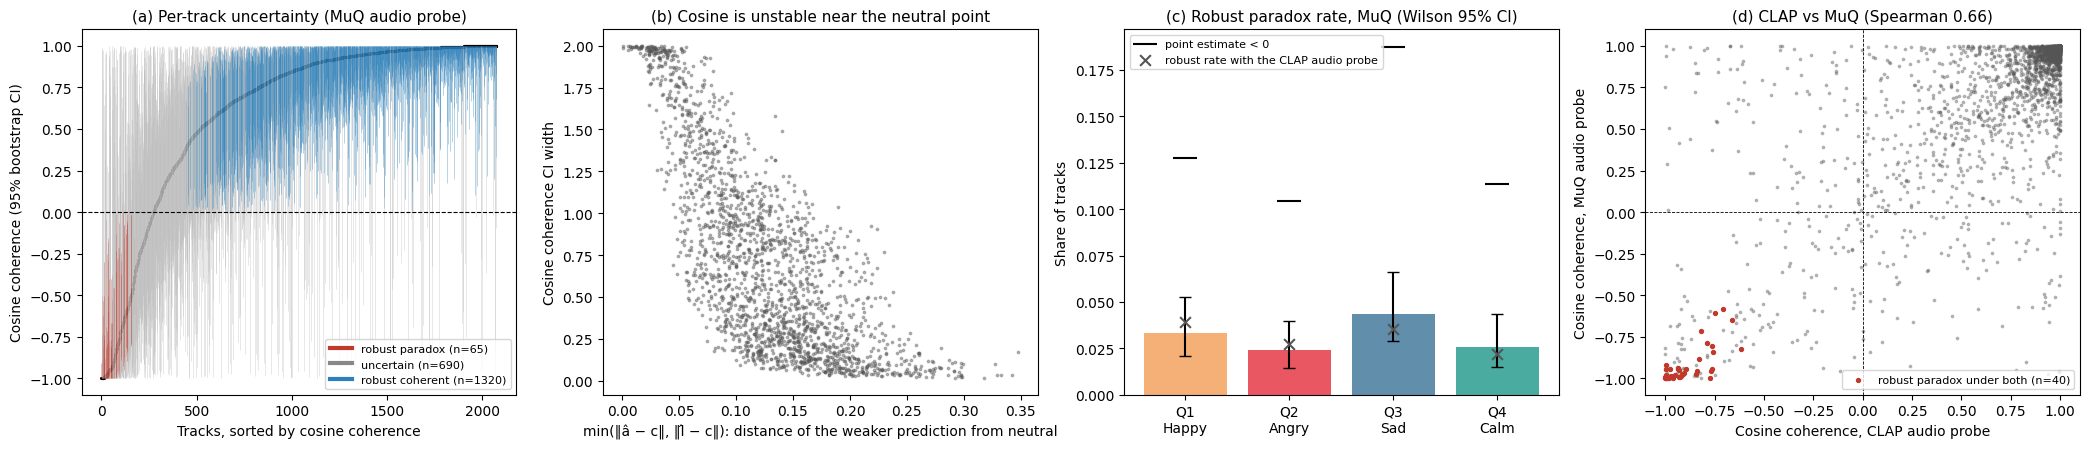

Saved: coherence_*_af.parquet/.csv, coherence_probe_oof_af.csv, coherence_probe_metrics_artist_disjoint.csv, coherence_uncertainty_muq_af.png


In [9]:
fig, axes = plt.subplots(1, 4, figsize=(21, 4.6))
ax = axes[0]
s = coh.sort_values('coh_cos').reset_index(drop=True)
colors = s.status_cos.map({'robust paradox': '#c0392b', 'uncertain': '#bbbbbb', 'robust coherent': '#2c7fb8'})
ax.vlines(s.index, s.coh_cos_lo, s.coh_cos_hi, colors=colors, lw=0.4, alpha=0.6)
ax.scatter(s.index, s.coh_cos, s=1.5, c='black'); ax.axhline(0, color='black', lw=0.8, ls='--')
ax.set_xlabel('Tracks, sorted by cosine coherence'); ax.set_ylabel('Cosine coherence (95% bootstrap CI)')
ax.set_title('(a) Per-track uncertainty (MuQ audio probe)', fontsize=11)
counts_st = coh.status_cos.value_counts()
for lbl, c in [('robust paradox', '#c0392b'), ('uncertain', '#888888'), ('robust coherent', '#2c7fb8')]:
    ax.plot([], [], color=c, lw=3, label=f'{lbl} (n={counts_st.get(lbl, 0)})')
ax.legend(fontsize=8, loc='lower right')
ax = axes[1]
ax.scatter(coh.min_dev_from_center, coh.coh_cos_ci_width, s=3, alpha=0.4, color='#555555')
ax.set_xlabel('min(‖â − c‖, ‖l̂ − c‖): distance of the weaker prediction from neutral'); ax.set_ylabel('Cosine coherence CI width')
ax.set_title('(b) Cosine is unstable near the neutral point', fontsize=11)
ax = axes[2]; x = np.arange(4)
clap_rate = [np.mean(clap.loc[np.array(sids)[quad == q], 'status_cos'] == 'robust paradox') for q in QUADS]
ax.bar(x, qtab.robust_paradox_rate, color=[QCOL[q] for q in QUADS], alpha=0.85,
       yerr=[qtab.robust_paradox_rate - qtab.robust_ci_lo, qtab.robust_ci_hi - qtab.robust_paradox_rate], capsize=4)
ax.scatter(x, qtab.point_paradox_rate, marker='_', s=300, color='black', label='point estimate < 0')
ax.scatter(x, clap_rate, marker='x', s=60, color='#555555', zorder=3, label='robust rate with the CLAP audio probe')
ax.set_xticks(x); ax.set_xticklabels([f'{q}\n{QLAB[q]}' for q in QUADS])
ax.set_ylabel('Share of tracks'); ax.set_title('(c) Robust paradox rate, MuQ (Wilson 95% CI)', fontsize=11); ax.legend(fontsize=8)
ax = axes[3]
ax.scatter(clap.coh_cos, cn.coh_cos, s=3, alpha=0.35, color='#555555')
ax.scatter(clap.loc[c2.index[both], 'coh_cos'], cn.loc[c2.index[both], 'coh_cos'], s=8, color='#c0392b',
           label=f'robust paradox under both (n={int(both.sum())})')
ax.axhline(0, color='black', lw=0.6, ls='--'); ax.axvline(0, color='black', lw=0.6, ls='--')
ax.set_xlabel('Cosine coherence, CLAP audio probe'); ax.set_ylabel('Cosine coherence, MuQ audio probe')
ax.set_title(f'(d) CLAP vs MuQ (Spearman {spearmanr(clap.coh_cos, cn.coh_cos)[0]:.2f})', fontsize=11)
ax.legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'coherence_uncertainty_muq_af_cg.png'), dpi=200, bbox_inches='tight'); plt.show()
print('Saved: coherence_*_af.parquet/.csv, coherence_probe_oof_af.csv, coherence_probe_metrics_artist_disjoint.csv, '
      'coherence_uncertainty_muq_af.png')